In [ ]:
!pip install gdown xgboost -q

import os, zipfile, glob, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 60)
RANDOM_STATE = 42

In [ ]:
!pip install gdown -q

file_id = '1mI8ULOWVjjFc5kvpTDSokRtZgiiWzAFB'
extract_dir = '/content/UNSW_NB15'
os.makedirs(extract_dir, exist_ok=True)

!gdown --id {file_id} -O /content/UNSW_NB15.zip

with zipfile.ZipFile('/content/UNSW_NB15.zip', 'r') as z:
    z.extractall(extract_dir)
    print("Extracted files:")
    for f in z.namelist():
        print(" ", f)

/usr/local/lib/python3.13/dist-packages/gdown/__main__.py:139: FutureWarning: Option `--id` was deprecated in version 4.3.1 and will be removed in 5.0. You don't need to pass it anymore to use a file ID.
  warnings.warn(
Downloading...
From (original): https://drive.google.com/uc?id=1mI8ULOWVjjFc5kvpTDSokRtZgiiWzAFB
From (redirected): https://drive.google.com/uc?id=1mI8ULOWVjjFc5kvpTDSokRtZgiiWzAFB&confirm=t&uuid=e2ee9c79-d448-4e7a-b8a4-3f5c410efb02
To: /content/UNSW_NB15.zip
100% 153M/153M [00:03<00:00, 38.6MB/s]
Extracted files:
  UNSW-NB15 data/UNSW-NB15_1.csv
  UNSW-NB15 data/UNSW-NB15_3.csv
  UNSW-NB15 data/UNSW-NB15_2.csv
  UNSW-NB15 data/NUSW-NB15_features.csv
  UNSW-NB15 data/UNSW-NB15_LIST_EVENTS.csv
  UNSW-NB15 data/UNSW_NB15_training-set.csv
  UNSW-NB15 data/UNSW_NB15_testing-set.csv
  UNSW-NB15 data/UNSW-NB15_4.csv


In [ ]:
csv_files = glob.glob(f'{extract_dir}/**/*.csv', recursive=True)
for f in csv_files:
    print(f"{os.path.getsize(f)/1e6:8.1f} MB  {f}")

train_path = next((f for f in csv_files if 'training-set' in f.lower()), None)
test_path  = next((f for f in csv_files if 'testing-set' in f.lower()), None)
assert train_path and test_path, "Could not find training-set / testing-set CSVs, check the listing above"

train_df = pd.read_csv(train_path)
test_df  = pd.read_csv(test_path)
print(train_df.shape, test_df.shape)

    32.3 MB  /content/UNSW_NB15/UNSW-NB15 data/UNSW_NB15_testing-set.csv
     0.0 MB  /content/UNSW_NB15/UNSW-NB15 data/UNSW-NB15_LIST_EVENTS.csv
   165.2 MB  /content/UNSW_NB15/UNSW-NB15 data/UNSW-NB15_2.csv
   169.0 MB  /content/UNSW_NB15/UNSW-NB15 data/UNSW-NB15_1.csv
    97.6 MB  /content/UNSW_NB15/UNSW-NB15 data/UNSW-NB15_4.csv
   154.6 MB  /content/UNSW_NB15/UNSW-NB15 data/UNSW-NB15_3.csv
    15.4 MB  /content/UNSW_NB15/UNSW-NB15 data/UNSW_NB15_training-set.csv
     0.0 MB  /content/UNSW_NB15/UNSW-NB15 data/NUSW-NB15_features.csv
(82332, 45) (175341, 45)


In [ ]:
display(train_df.head())
print(train_df.dtypes.value_counts(), '\n')
print('Missing values  train:', train_df.isna().sum().sum(), ' test:', test_df.isna().sum().sum())
print('Duplicate rows (train, ignoring id):',
      train_df.drop(columns=['id'], errors='ignore').duplicated().sum())
display(train_df.describe().T)

,id,dur,proto,service,state,spkts,dpkts,sbytes,dbytes,rate,sttl,dttl,sload,dload,sloss,dloss,sinpkt,dinpkt,sjit,djit,swin,stcpb,dtcpb,dwin,tcprtt,synack,ackdat,smean,dmean,trans_depth,response_body_len,ct_srv_src,ct_state_ttl,ct_dst_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,is_ftp_login,ct_ftp_cmd,ct_flw_http_mthd,ct_src_ltm,ct_srv_dst,is_sm_ips_ports,attack_cat,label
0,1,0.000011,udp,-,INT,2,0,496,0,90909.0902,254,0,180363632.0,0.0,0,0,0.011,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,248,0,0,0,2,2,1,1,1,2,0,0,0,1,2,0,Normal,0
1,2,0.000008,udp,-,INT,2,0,1762,0,125000.0003,254,0,881000000.0,0.0,0,0,0.008,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,881,0,0,0,2,2,1,1,1,2,0,0,0,1,2,0,Normal,0
2,3,0.000005,udp,-,INT,2,0,1068,0,200000.0051,254,0,854400000.0,0.0,0,0,0.005,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,534,0,0,0,3,2,1,1,1,3,0,0,0,1,3,0,Normal,0
3,4,0.000006,udp,-,INT,2,0,900,0,166666.6608,254,0,600000000.0,0.0,0,0,0.006,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,450,0,0,0,3,2,2,2,1,3,0,0,0,2,3,0,Normal,0
4,5,0.000010,udp,-,INT,2,0,2126,0,100000.0025,254,0,850400000.0,0.0,0,0,0.010,0.0,0.0,0.0,0,0,0,0,0.0,0.0,0.0,1063,0,0,0,3,2,2,2,1,3,0,0,0,2,3,0,Normal,0


int64      30
float64    11
object      4
Name: count, dtype: int64 

Missing values  train: 0  test: 0
Duplicate rows (train, ignoring id): 26387


,count,mean,std,min,25%,50%,75%,max
id,82332.0,4.116650e+04,2.376735e+04,1.0,20583.750000,4.116650e+04,6.174925e+04,8.233200e+04
dur,82332.0,1.006756e+00,4.710444e+00,0.0,0.000008,1.413800e-02,7.193603e-01,5.999999e+01
spkts,82332.0,1.866647e+01,1.339164e+02,1.0,2.000000,6.000000e+00,1.200000e+01,1.064600e+04
dpkts,82332.0,1.754594e+01,1.155741e+02,0.0,0.000000,2.000000e+00,1.000000e+01,1.101800e+04
sbytes,82332.0,7.993908e+03,1.716423e+05,24.0,114.000000,5.340000e+02,1.280000e+03,1.435577e+07
dbytes,82332.0,1.323379e+04,1.514715e+05,0.0,0.000000,1.780000e+02,9.560000e+02,1.465753e+07
rate,82332.0,8.241089e+04,1.486204e+05,0.0,28.606114,2.650177e+03,1.111111e+05,1.000000e+06
sttl,82332.0,1.809677e+02,1.015134e+02,0.0,62.000000,2.540000e+02,2.540000e+02,2.550000e+02
dttl,82332.0,9.571300e+01,1.166677e+02,0.0,0.000000,2.900000e+01,2.520000e+02,2.530000e+02
sload,82332.0,6.454902e+07,1.798618e+08,0.0,11202.466797,5.770032e+05,6.514286e+07,5.268000e+09


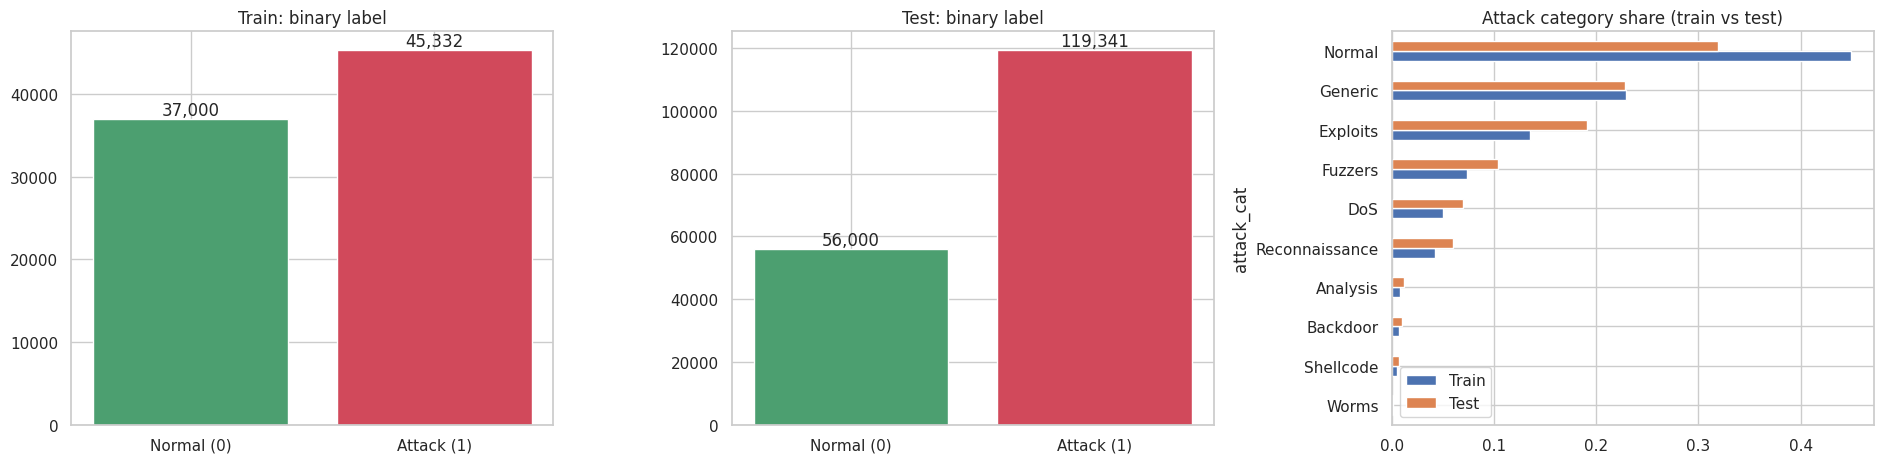

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))

for ax, (name, df) in zip(axes[:2], [('Train', train_df), ('Test', test_df)]):
    counts = df['label'].value_counts().sort_index()
    ax.bar(['Normal (0)', 'Attack (1)'], counts.values, color=['#4C9F70', '#D1495B'])
    for i, v in enumerate(counts.values):
        ax.text(i, v, f'{v:,}', ha='center', va='bottom')
    ax.set_title(f'{name}: binary label')

cat_share = pd.DataFrame({
    'Train': train_df['attack_cat'].value_counts(normalize=True),
    'Test':  test_df['attack_cat'].value_counts(normalize=True)
}).fillna(0).sort_values('Train')
cat_share.plot.barh(ax=axes[2])
axes[2].set_title('Attack category share (train vs test)')

plt.tight_layout()
plt.show()

proto: 131 unique in train, 133 in test
service: 13 unique in train, 13 in test
state: 7 unique in train, 9 in test
Categories only in test: {'proto': {'rtp', 'icmp'}, 'service': set(), 'state': {'URN', 'ECO', 'no', 'PAR'}}


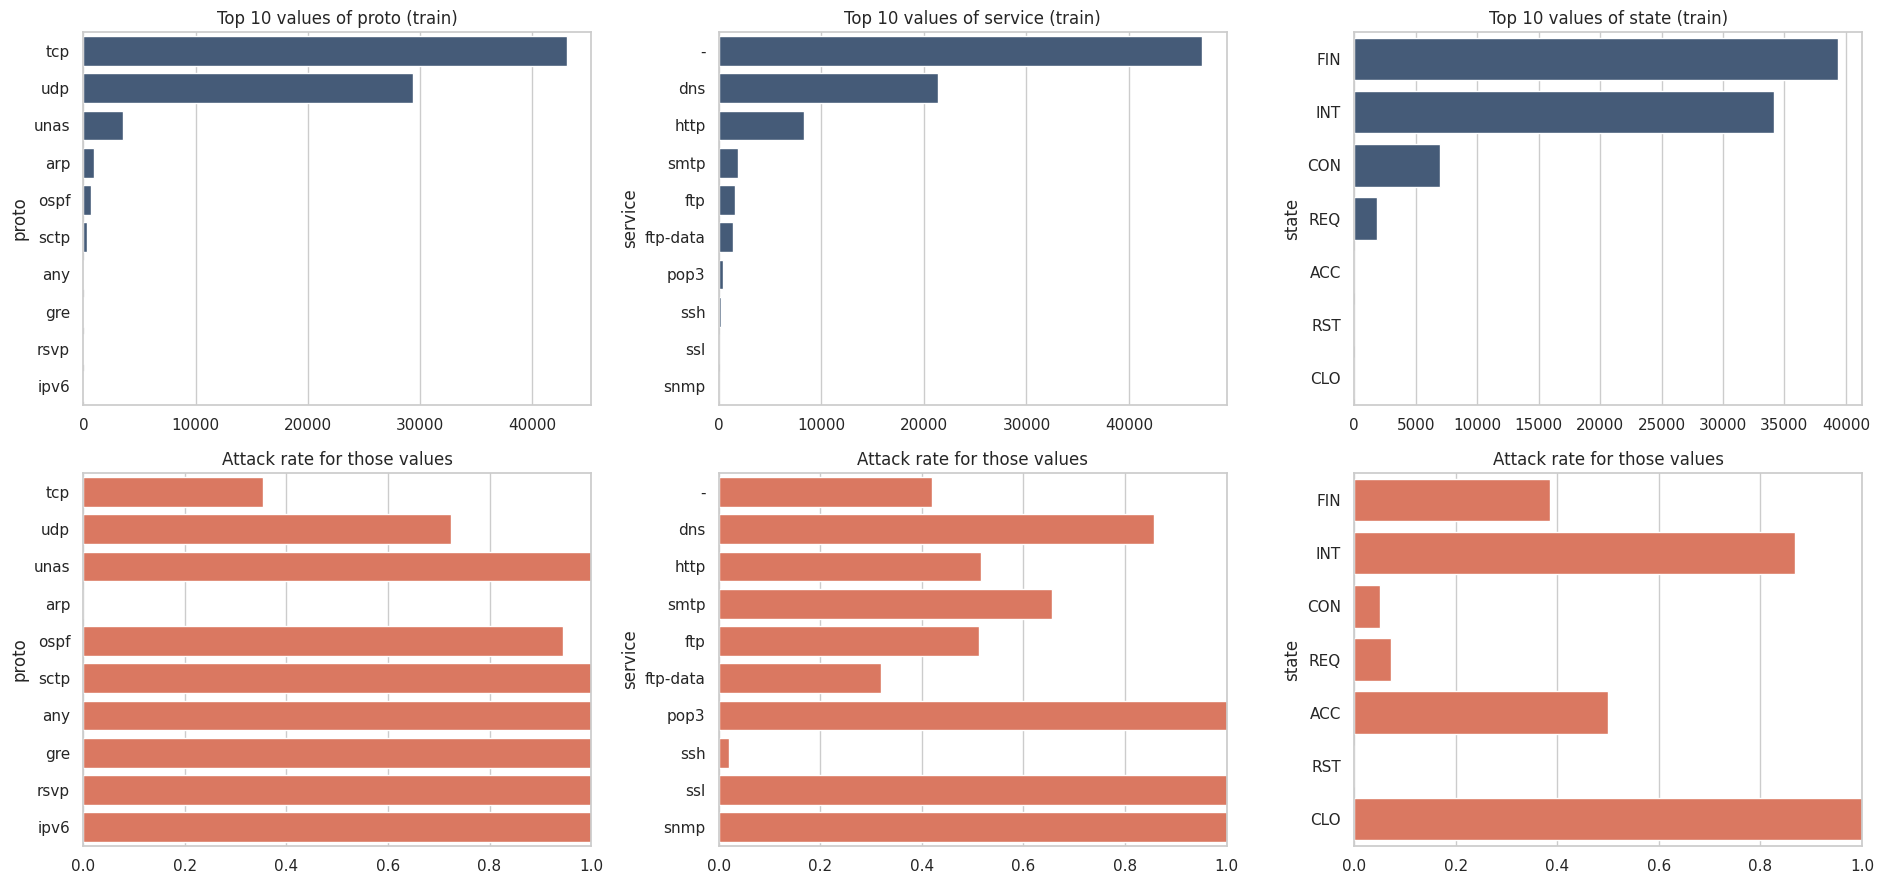

In [ ]:
cat_cols = ['proto', 'service', 'state']

for c in cat_cols:
    print(f"{c}: {train_df[c].nunique()} unique in train, {test_df[c].nunique()} in test")
print('Categories only in test:', {c: set(test_df[c]) - set(train_df[c]) for c in cat_cols})

fig, axes = plt.subplots(2, 3, figsize=(19, 9))
for i, c in enumerate(cat_cols):
    top = train_df[c].value_counts().head(10)
    sns.barplot(x=top.values, y=top.index, ax=axes[0, i], color='#3D5A80')
    axes[0, i].set_title(f'Top 10 values of {c} (train)')

    top_idx = top.index
    rate = train_df[train_df[c].isin(top_idx)].groupby(c)['label'].mean().loc[top_idx]
    sns.barplot(x=rate.values, y=rate.index, ax=axes[1, i], color='#EE6C4D')
    axes[1, i].set_title(f'Attack rate for those values')
    axes[1, i].set_xlim(0, 1)

plt.tight_layout()
plt.show()

trans_depth          170.794394
response_body_len     74.635200
djit                  60.562275
dloss                 54.465649
sbytes                53.778546
dbytes                52.550387
sloss                 52.465277
dpkts                 49.304127
spkts                 47.747777
dinpkt                23.013046
sjit                  15.349380
synack                13.809682
ct_flw_http_mthd      12.557680
ct_ftp_cmd            11.243182
is_ftp_login          11.042308
dtype: float64


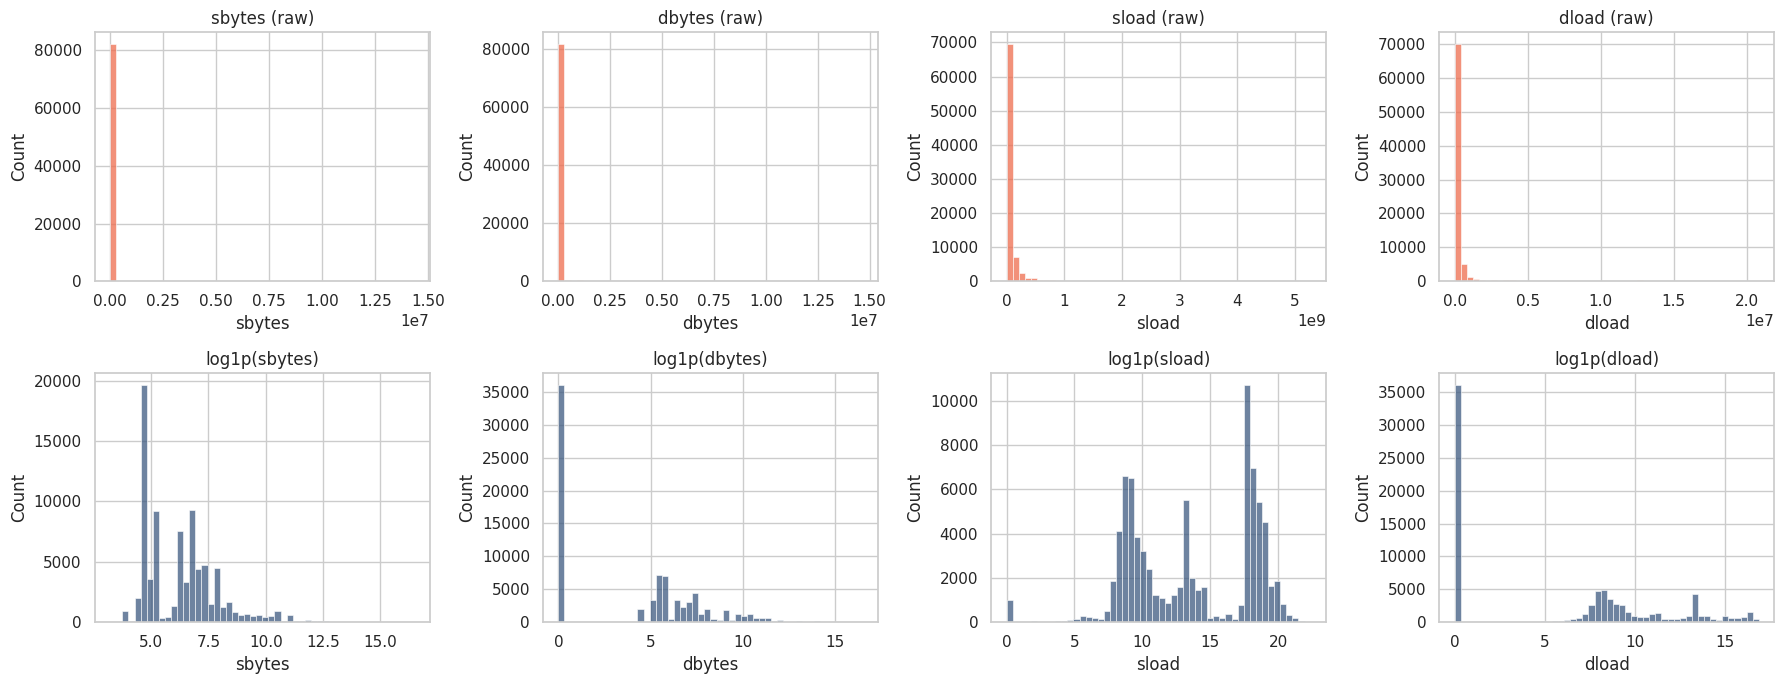

In [ ]:
exclude = ['id', 'label', 'attack_cat'] + cat_cols
num_cols_all = [c for c in train_df.columns if c not in exclude]

print(train_df[num_cols_all].skew().sort_values(ascending=False).head(15))

show = [c for c in ['sbytes', 'dbytes', 'sload', 'dload'] if c in train_df.columns]
fig, axes = plt.subplots(2, len(show), figsize=(4.5 * len(show), 7))
for i, c in enumerate(show):
    sns.histplot(train_df[c], bins=50, ax=axes[0, i], color='#EE6C4D')
    axes[0, i].set_title(f'{c} (raw)')
    sns.histplot(np.log1p(train_df[c].clip(lower=0)), bins=50, ax=axes[1, i], color='#3D5A80')
    axes[1, i].set_title(f'log1p({c})')
plt.tight_layout()
plt.show()

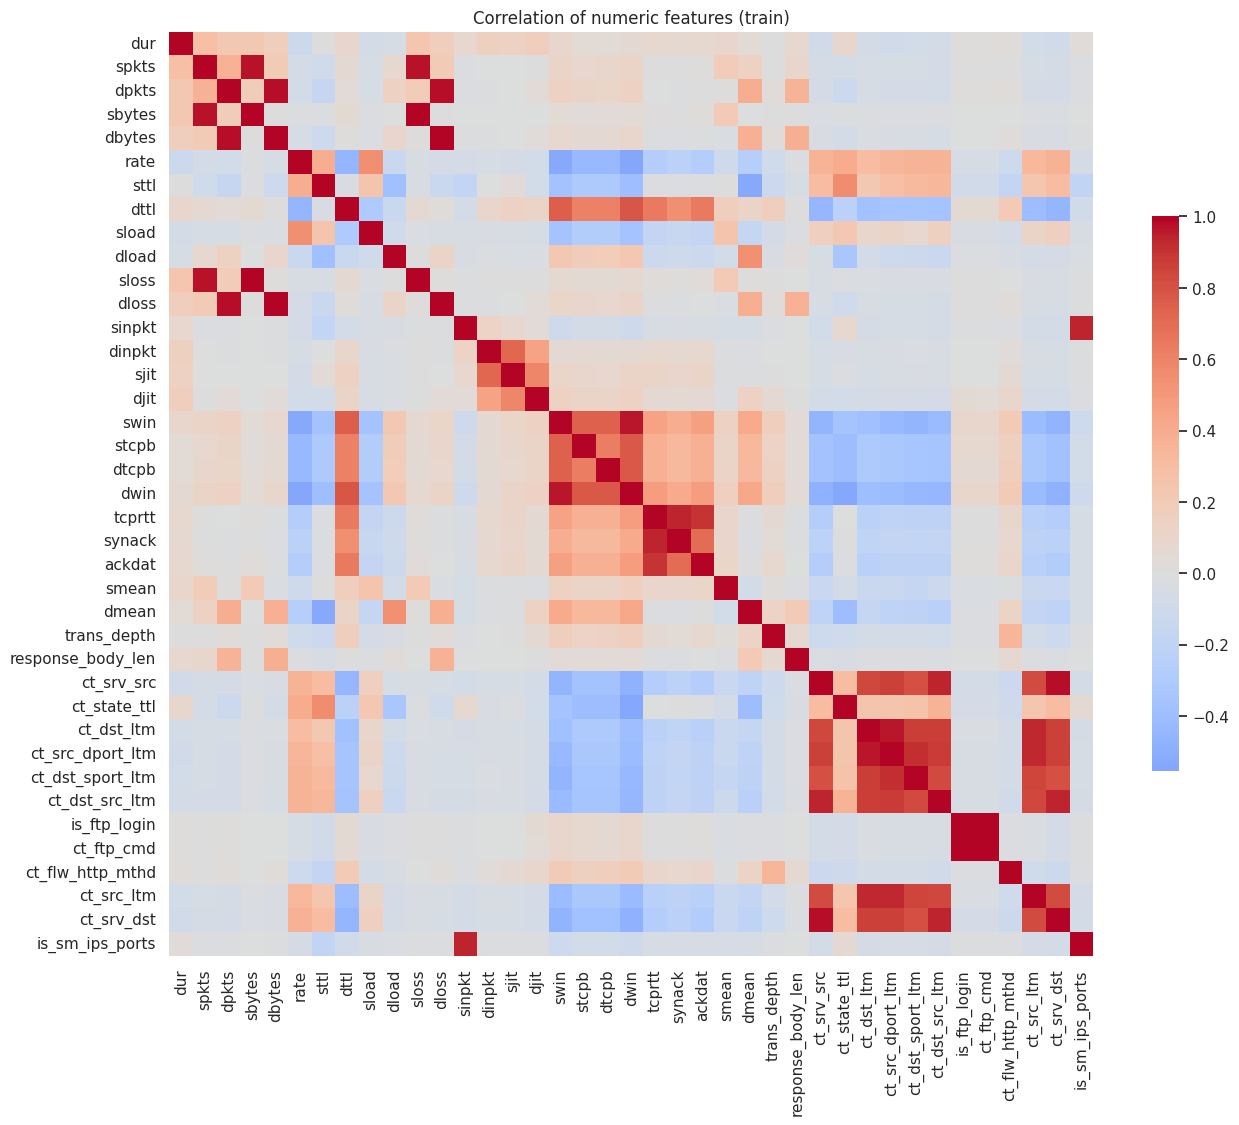

Features with |corr| > 0.95 against another feature: ['sbytes', 'dbytes', 'sloss', 'dloss', 'dwin', 'ct_src_dport_ltm', 'ct_ftp_cmd', 'ct_srv_dst']


In [ ]:
corr = train_df[num_cols_all].corr()

plt.figure(figsize=(15, 12))
sns.heatmap(corr, cmap='coolwarm', center=0, square=True, cbar_kws={'shrink': 0.6})
plt.title('Correlation of numeric features (train)')
plt.show()

upper = corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_corr = [c for c in upper.columns if (upper[c] > 0.95).any()]
print('Features with |corr| > 0.95 against another feature:', high_corr)

In [ ]:
drop_cols = ['id', 'attack_cat', 'label']
X_train = train_df.drop(columns=drop_cols, errors='ignore')
X_test  = test_df.drop(columns=drop_cols, errors='ignore')
y_train, y_test = train_df['label'], test_df['label']

num_cols = [c for c in X_train.columns if c not in cat_cols]
skewed  = [c for c in num_cols
           if X_train[c].min() >= 0 and X_train[c].skew() > 5 and X_train[c].nunique() > 10]
regular = [c for c in num_cols if c not in skewed]

print(f'{len(skewed)} log-transformed, {len(regular)} plain numeric, {len(cat_cols)} categorical')
print('Log-transformed:', skewed)

16 log-transformed, 23 plain numeric, 3 categorical
Log-transformed: ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'sload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'tcprtt', 'synack', 'ackdat', 'response_body_len']


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

log_pipe = Pipeline([
    ('log', FunctionTransformer(np.log1p, feature_names_out='one-to-one')),
    ('scale', StandardScaler())
])

preprocess = ColumnTransformer([
    ('log', log_pipe, skewed),
    ('num', StandardScaler(), regular),
    ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=50, sparse_output=False), cat_cols)
])

Xtr = preprocess.fit_transform(X_train)
Xte = preprocess.transform(X_test)
feature_names = preprocess.get_feature_names_out()
print(Xtr.shape, Xte.shape)

(82332, 69) (175341, 69)


In [ ]:
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

models = {
    'XGBoost': XGBClassifier(n_estimators=300, max_depth=8, learning_rate=0.1,
                             subsample=0.8, colsample_bytree=0.8, tree_method='hist',
                             n_jobs=-1, random_state=RANDOM_STATE, eval_metric='logloss'),
    'RandomForest': RandomForestClassifier(n_estimators=200, n_jobs=-1,
                                           class_weight='balanced', random_state=RANDOM_STATE)
}

results, probas = {}, {}
for name, m in models.items():
    m.fit(Xtr, y_train)
    p = m.predict_proba(Xte)[:, 1]
    pred = (p >= 0.5).astype(int)
    probas[name] = p
    results[name] = {
        'accuracy':  accuracy_score(y_test, pred),
        'precision': precision_score(y_test, pred),
        'recall':    recall_score(y_test, pred),
        'f1':        f1_score(y_test, pred),
        'roc_auc':   roc_auc_score(y_test, p),
    }

res_df = pd.DataFrame(results).T.round(4)
display(res_df)

,accuracy,precision,recall,f1,roc_auc
XGBoost,0.9005,0.9892,0.8632,0.9219,0.9858
RandomForest,0.9037,0.9871,0.8699,0.9248,0.9830


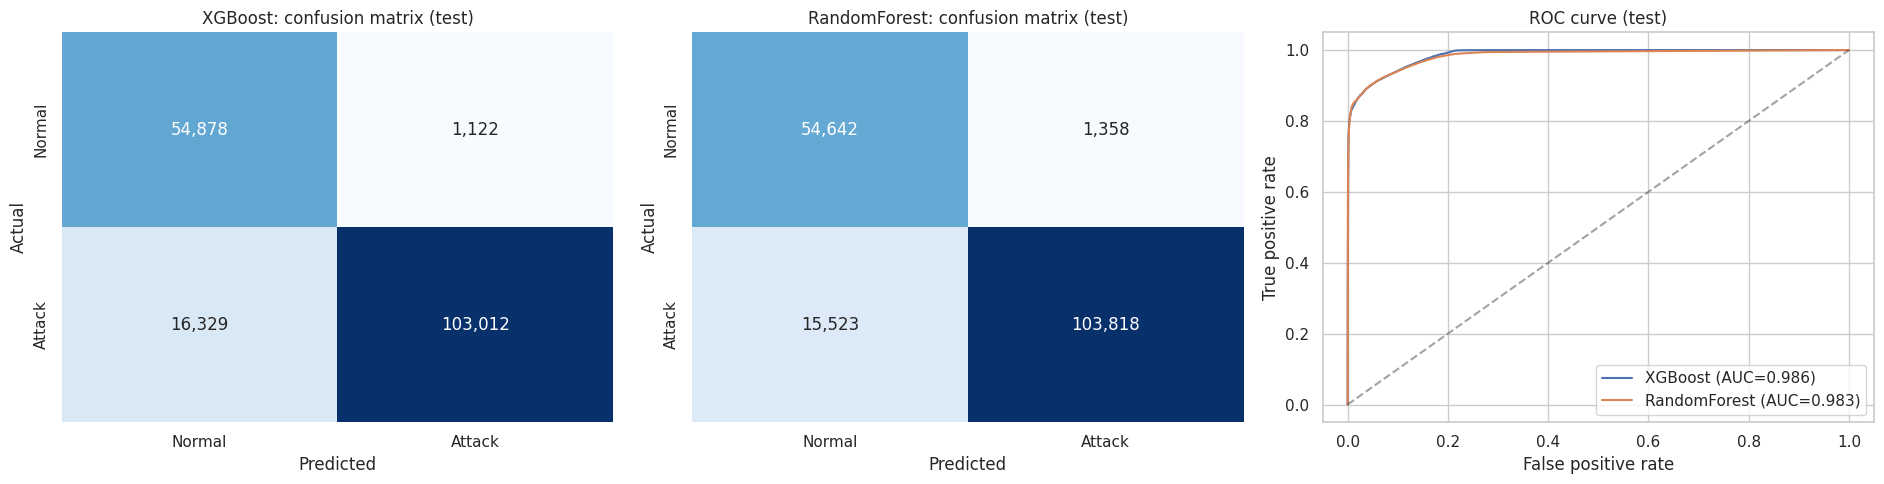

In [ ]:
from sklearn.metrics import confusion_matrix, roc_curve

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

for ax, name in zip(axes[:2], models):
    cm = confusion_matrix(y_test, (probas[name] >= 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt=',d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Normal', 'Attack'], yticklabels=['Normal', 'Attack'])
    ax.set_title(f'{name}: confusion matrix (test)')
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')

for name in models:
    fpr, tpr, _ = roc_curve(y_test, probas[name])
    axes[2].plot(fpr, tpr, label=f"{name} (AUC={results[name]['roc_auc']:.3f})")
axes[2].plot([0, 1], [0, 1], 'k--', alpha=0.4)
axes[2].set_title('ROC curve (test)')
axes[2].set_xlabel('False positive rate'); axes[2].set_ylabel('True positive rate')
axes[2].legend()

plt.tight_layout()
plt.show()

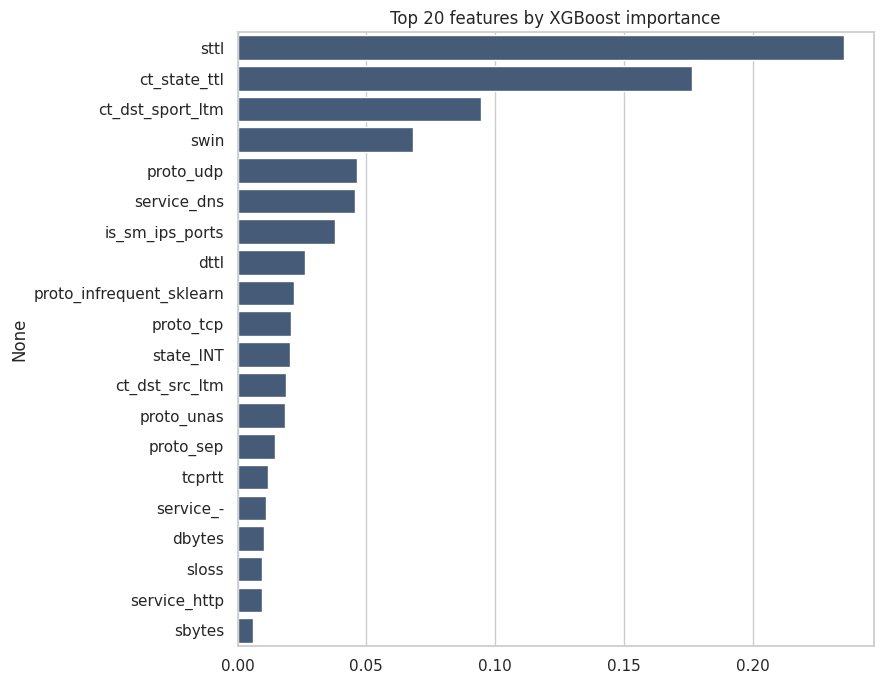

Top raw features: ['sttl', 'ct_state_ttl', 'ct_dst_sport_ltm', 'swin', 'proto', 'service', 'is_sm_ips_ports', 'dttl', 'state', 'ct_dst_src_ltm']


In [ ]:
xgb = models['XGBoost']
imp = pd.Series(xgb.feature_importances_,
                index=[n.split('__', 1)[1] for n in feature_names]).sort_values(ascending=False)

plt.figure(figsize=(9, 7))
sns.barplot(x=imp.head(20).values, y=imp.head(20).index, color='#3D5A80')
plt.title('Top 20 features by XGBoost importance')
plt.tight_layout()
plt.show()

def raw_name(n):
    for c in cat_cols:
        if n.startswith(c + '_'):
            return c
    return n
top_raw = list(dict.fromkeys(raw_name(n) for n in imp.index))[:10]
print('Top raw features:', top_raw)

In [ ]:
from google.colab import drive
import joblib, sklearn, xgboost

drive.mount('/content/drive')
out_dir = '/content/drive/MyDrive/nids_project/artifacts'
os.makedirs(out_dir, exist_ok=True)

defaults = {c: (float(X_train[c].median()) if c in num_cols else str(X_train[c].mode()[0]))
            for c in X_train.columns}

meta = {
    'cat_cols': cat_cols, 'skewed_cols': skewed, 'regular_cols': regular,
    'raw_feature_order': list(X_train.columns),
    'top_raw_features': top_raw,
    'defaults': defaults,
    'baseline_metrics': results,
    'versions': {'sklearn': sklearn.__version__, 'xgboost': xgboost.__version__,
                 'pandas': pd.__version__, 'numpy': np.__version__},
}

joblib.dump(preprocess, f'{out_dir}/preprocess.joblib')
joblib.dump(models['XGBoost'], f'{out_dir}/baseline_xgb.joblib')
with open(f'{out_dir}/meta.json', 'w') as f:
    json.dump(meta, f, indent=2)

train_df.to_parquet(f'{out_dir}/train.parquet')
test_df.to_parquet(f'{out_dir}/test.parquet')
print('Saved:', os.listdir(out_dir))

Mounted at /content/drive
Saved: ['preprocess.joblib', 'baseline_xgb.joblib', 'meta.json', 'train.parquet', 'test.parquet']
